# Predicting Risk of Lifestyle-Related Diseases Using Patient Health Data

1. Import Libraries
2. Load & First Inspection
3. Drop Irrelevant Column
4. Drop Duplicates *(must happen on raw data, before any cleaning)*
5. Data Cleaning — Parse String Columns to Numeric
6. EDA — Raw Distributions & Skewness *(before touching values)*
7. Remove Impossible / Invalid Values
8. Missing Value Imputation
9. Outlier Detection & Treatment 
10. Feature Engineering
11. Encoding Categorical Variables
12. Correlation & Multicollinearity Check
13. Train / Test Split
14. Scaling
15. Model Evaluations

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_score, recall_score, f1_score,
    classification_report, roc_auc_score,
    roc_curve, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')


## 2. Load Data & First Inspection

Before modifying anything, we explore the dataset to understand:
- Shape (rows × columns)
- Data types — which columns are stored incorrectly as `object`
- Missing value counts per column
- Basic statistics (min, max, mean) to spot obvious anomalies

In [2]:
df = pd.read_csv('diabetes.csv')
print('Shape:', df.shape)
print('\nColumn names:', df.columns.tolist())
df.head()


Shape: (9990, 12)

Column names: ['patient_id', 'age', 'gender', 'bmi', 'fasting_glucose_mg_dl', 'hba1c_percent', 'insulin_uU_ml', 'blood_pressure_systolic', 'family_history_diabetes', 'physical_activity_level', 'num_pregnancies', 'diabetes']


,patient_id,age,gender,bmi,fasting_glucose_mg_dl,hba1c_percent,insulin_uU_ml,blood_pressure_systolic,family_history_diabetes,physical_activity_level,num_pregnancies,diabetes
0,PAT33910,55.14,Female,17.5,73.6 mg/dL,4.79%,26.23,109 mmHg,No,High,0,No
1,PAT13565,67.95,Female,30.6,145.1 mg/dL,6.4%,23.36,NaN,No,Sedentary,2,Yes
2,PAT14157,59.27,Female,36.4,90.7 mg/dL,4.77%,3.68,139 mmHg,Yes,Low,4,Yes
3,PAT67909,57.19,Female,27.3,156.4 mg/dL,5.92%,2.24,NaN,No,Low,2,Yes
4,PAT38295,59.43,Male,22.6,112.1 mg/dL,5.44%,NaN,138 mmHg,No,Moderate,0,No


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9990 entries, 0 to 9989
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               9990 non-null   object 
 1   age                      9842 non-null   float64
 2   gender                   9990 non-null   object 
 3   bmi                      9647 non-null   float64
 4   fasting_glucose_mg_dl    9389 non-null   object 
 5   hba1c_percent            9300 non-null   object 
 6   insulin_uU_ml            9181 non-null   float64
 7   blood_pressure_systolic  9618 non-null   object 
 8   family_history_diabetes  9990 non-null   object 
 9   physical_activity_level  9990 non-null   object 
 10  num_pregnancies          9990 non-null   int64  
 11  diabetes                 9990 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 936.7+ KB


In [4]:
df.describe()

,age,bmi,insulin_uU_ml,num_pregnancies
count,9842.000000,9647.000000,9181.000000,9990.000000
mean,48.013076,29.552472,17.727124,0.994695
std,15.579563,7.190028,21.516939,1.614354
min,-3.000000,6.300000,2.000000,0.000000
25%,35.250000,24.700000,6.620000,0.000000
50%,47.950000,29.000000,11.460000,0.000000
75%,60.400000,33.600000,20.210000,2.000000
max,116.900000,130.000000,250.000000,9.000000


In [5]:
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
patient_id                   0
age                        148
gender                       0
bmi                        343
fasting_glucose_mg_dl      601
hba1c_percent              690
insulin_uU_ml              809
blood_pressure_systolic    372
family_history_diabetes      0
physical_activity_level      0
num_pregnancies              0
diabetes                     0
dtype: int64


## 3. Drop Irrelevant Column

`patient_id` is just a unique identifier — it carries no predictive information for diabetes.
Keeping it could cause the model to memorise IDs instead of learning real patterns.

In [6]:
df.drop('patient_id', axis=1, inplace=True)
print('Remaining columns:', df.columns.tolist())


Remaining columns: ['age', 'gender', 'bmi', 'fasting_glucose_mg_dl', 'hba1c_percent', 'insulin_uU_ml', 'blood_pressure_systolic', 'family_history_diabetes', 'physical_activity_level', 'num_pregnancies', 'diabetes']


## 4. Drop Duplicate Rows

Duplicates must be removed on the raw data. If we impute or clean first, two originally identical rows may become slightly different (e.g. one has a null filled with median, the other had the actual value) — pandas would then no longer recognise them as duplicates and we would fail to remove them.

After dropping, we reset the index so row numbers are continuous from 0.

In [7]:
print('Duplicate rows before drop:', df.duplicated().sum())

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print('Duplicate rows after drop: ', df.duplicated().sum())
print('Shape after deduplication:', df.shape)


Duplicate rows before drop: 417
Duplicate rows after drop:  0
Shape after deduplication: (9573, 11)


## 5. Data Cleaning — Parse String Columns to Numeric

Three columns contain numeric values but are stored as strings because of unit suffixes:
- `fasting_glucose_mg_dl` → values like `"114.7 mg/dL"`
- `hba1c_percent` → values like `"5.35%"`
- `blood_pressure_systolic` → values like `"123 mmHg"`


In [8]:

print('fasting_glucose sample:', df['fasting_glucose_mg_dl'].dropna().unique()[:5])
print('hba1c sample:          ', df['hba1c_percent'].dropna().unique()[:5])
print('blood_pressure sample: ', df['blood_pressure_systolic'].dropna().unique()[:5])


fasting_glucose sample: ['73.6 mg/dL' '145.1 mg/dL' '90.7 mg/dL' '156.4 mg/dL' '112.1 mg/dL']
hba1c sample:           ['4.79%' '6.4%' '4.77%' '5.92%' '5.44%']
blood_pressure sample:  ['109 mmHg' '139 mmHg' '138 mmHg' '110 mmHg' '129 mmHg']


In [9]:
# We strip the units and convert to numbers

df['fasting_glucose_mg_dl'] = pd.to_numeric(
    df['fasting_glucose_mg_dl'].str.replace(' mg/dL', '', regex=False), errors='coerce')

df['hba1c_percent'] = pd.to_numeric(
    df['hba1c_percent'].str.replace('%', '', regex=False), errors='coerce')

df['blood_pressure_systolic'] = pd.to_numeric(
    df['blood_pressure_systolic'].str.replace(' mmHg', '', regex=False), errors='coerce')

print('Dtypes after parsing:')
print(df.dtypes)


Dtypes after parsing:
age                        float64
gender                      object
bmi                        float64
fasting_glucose_mg_dl      float64
hba1c_percent              float64
insulin_uU_ml              float64
blood_pressure_systolic    float64
family_history_diabetes     object
physical_activity_level     object
num_pregnancies              int64
diabetes                    object
dtype: object


## 6. EDA — Raw Distributions & Skewness

**Skewness rule of thumb:**
- |skew| < 0.5 → approximately normal → mean imputation is fine
- 0.5 ≤ |skew| < 2 → moderately skewed → prefer median
- |skew| ≥ 2 → highly skewed → must use median

Skewness of numeric columns:
insulin_uU_ml              4.546
bmi                        1.879
num_pregnancies            1.860
fasting_glucose_mg_dl      1.790
hba1c_percent              1.340
blood_pressure_systolic    0.081
age                        0.075
dtype: float64


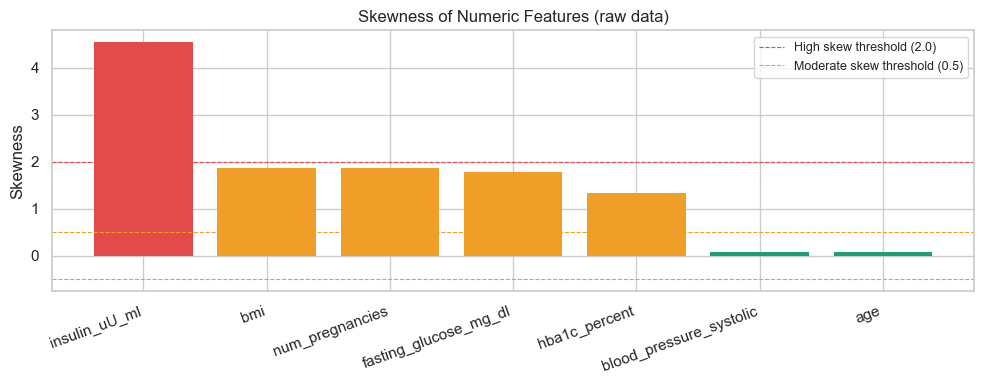

In [10]:
num_cols = ['age', 'bmi', 'fasting_glucose_mg_dl', 'hba1c_percent',
            'insulin_uU_ml', 'blood_pressure_systolic', 'num_pregnancies']

skewness = df[num_cols].skew().sort_values(ascending=False)
print('Skewness of numeric columns:')
print(skewness.round(3))

# Visualise skewness
colors = ['#E24B4A' if abs(v) >= 2 else '#EF9F27' if abs(v) >= 0.5 else '#1D9E75'
          for v in skewness]

plt.figure(figsize=(10, 4))
bars = plt.bar(skewness.index, skewness.values, color=colors, edgecolor='none')
plt.axhline(2,  color='#E24B4A', linestyle='--', linewidth=0.8, label='High skew threshold (2.0)')
plt.axhline(0.5,color='#EF9F27', linestyle='--', linewidth=0.8, label='Moderate skew threshold (0.5)')
plt.axhline(-0.5,color='#EF9F27',linestyle='--', linewidth=0.8)
plt.title('Skewness of Numeric Features (raw data)')
plt.ylabel('Skewness')
plt.xticks(rotation=20, ha='right')
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


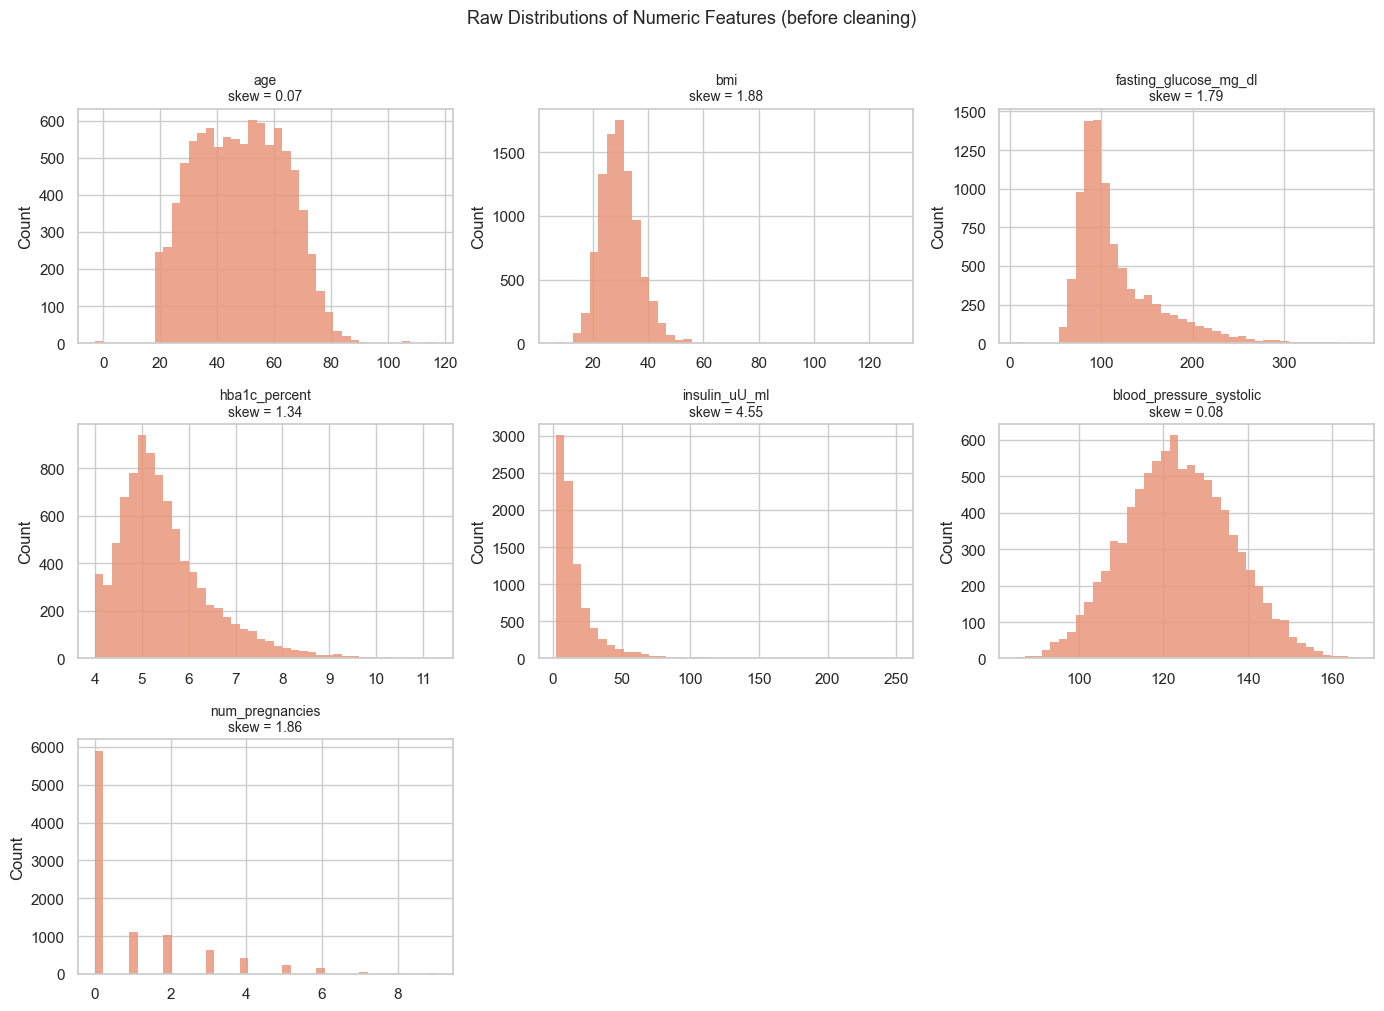

In [11]:
# Distribution histograms — raw data 

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=40, color='darksalmon', edgecolor='none', alpha=0.85)
    axes[i].set_title(f'{col}\nskew = {df[col].skew():.2f}', fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Raw Distributions of Numeric Features (before cleaning)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


Target class counts:
diabetes
No     5993
Yes    3580
Name: count, dtype: int64

Class balance: 62.6% No  /  37.4% Yes


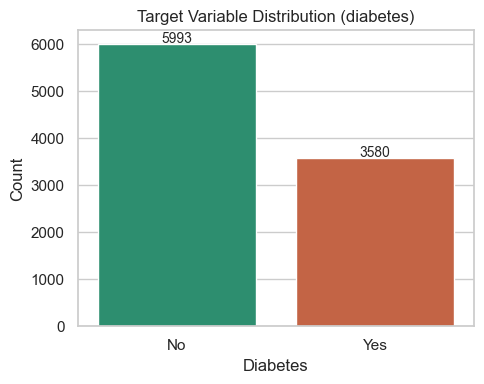

In [12]:
# Target variable distribution

counts = df['diabetes'].value_counts()
print('Target class counts:')
print(counts)
print(f'\nClass balance: {counts["No"]/len(df)*100:.1f}% No  /  {counts["Yes"]/len(df)*100:.1f}% Yes')

plt.figure(figsize=(5, 4))
sns.countplot(x='diabetes', data=df, palette=['#1D9E75', '#D85A30'])
plt.title('Target Variable Distribution (diabetes)')
plt.xlabel('Diabetes')
plt.ylabel('Count')
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}',
                       (p.get_x() + p.get_width()/2, p.get_height() + 30),
                       ha='center', fontsize=10)
plt.tight_layout()
plt.show()


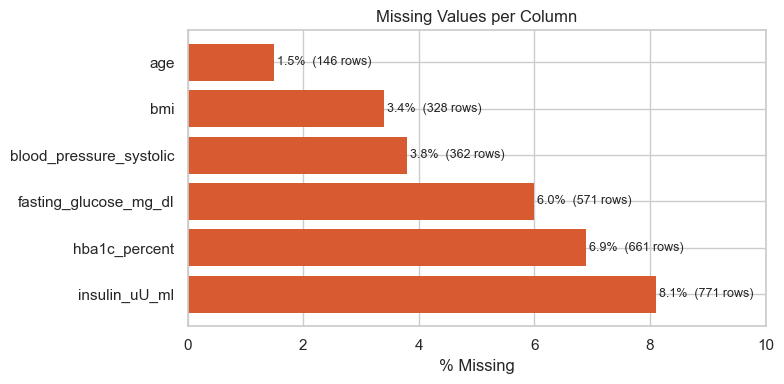

In [13]:
# Missing value visualisation

null_counts = df.isnull().sum().sort_values(ascending=False)
null_counts = null_counts[null_counts > 0]
null_pct = (null_counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(null_counts.index, null_pct.values, color='#D85A30', edgecolor='none')
for bar, pct, cnt in zip(bars, null_pct.values, null_counts.values):
    ax.text(pct + 0.05, bar.get_y() + bar.get_height()/2,
            f'{pct}%  ({cnt} rows)', va='center', fontsize=9)
ax.set_xlabel('% Missing')
ax.set_title('Missing Values per Column')
ax.set_xlim(0, 10)
plt.tight_layout()
plt.show()

## 7. Remove Impossible / Invalid Values

Some rows contain biologically impossible values discovered from `describe()` earlier:
- `age < 0` — a person cannot have negative age
- `age > 100` — beyond plausible range for a clinical study
- `bmi < 10` — not survivable
- `fasting_glucose < 30` — incompatible with life


In [14]:
print('Shape before invalid value removal:', df.shape)

df = df[(df['age'].isna()) | ((df['age'] > 0) & (df['age'] <= 100))]
df = df[(df['bmi'].isna()) | (df['bmi'] > 10)]
df = df[(df['fasting_glucose_mg_dl'].isna()) | (df['fasting_glucose_mg_dl'] > 30)]
df = df[(df['insulin_uU_ml'].isna()) | (df['insulin_uU_ml'] > 0)]
df = df[(df['blood_pressure_systolic'].isna()) | (df['blood_pressure_systolic'] > 50)]

df.reset_index(drop=True, inplace=True)
print('Shape after invalid value removal: ', df.shape)


Shape before invalid value removal: (9573, 11)
Shape after invalid value removal:  (9539, 11)


## 8. Missing Value Imputation

Before filling nulls, we must understand *why* values are missing:                  
Our nulls are **MCAR** — about 5% spread evenly with no visible pattern. Median imputation is appropriate.

### Why Median (not Mean) for all columns?

From the skewness analysis in Section 6:
- `insulin` skew = 6.64 → extreme right skew → **median**
- `fasting_glucose` skew = 5.74 → extreme right skew → **median** *(corrected from original)*
- `hba1c_percent` skew = 2.10 → high skew → **median** *(corrected from original)*
- `bmi` skew = 4.16 → high skew → **median**
- `age` skew = 0.95 → moderate skew → **median**
- `blood_pressure` skew = 0.06 → near-normal → mean or median; we use **median** for consistency

Using **mean on skewed data** pulls the imputed value toward the long tail, introducing bias into every row that had a missing value.


In [15]:
print('Missing values BEFORE imputation:')
print(df.isnull().sum())


Missing values BEFORE imputation:
age                        146
gender                       0
bmi                        328
fasting_glucose_mg_dl      570
hba1c_percent              660
insulin_uU_ml              768
blood_pressure_systolic    362
family_history_diabetes      0
physical_activity_level      0
num_pregnancies              0
diabetes                     0
dtype: int64


In [16]:
# age and blood_pressure are near-normal (|skew| < 0.5) → mean
# bmi, glucose, hba1c, insulin are right-skewed → median

mean_cols   = ['age', 'blood_pressure_systolic']
median_cols = ['bmi', 'fasting_glucose_mg_dl', 'hba1c_percent', 'insulin_uU_ml']

mean_imputer   = SimpleImputer(strategy='mean')
median_imputer = SimpleImputer(strategy='median')

df[mean_cols]   = mean_imputer.fit_transform(df[mean_cols])
df[median_cols] = median_imputer.fit_transform(df[median_cols])

df['age'] = df['age'].round().astype(int)

print('\nMissing values AFTER imputation:')
print(df.isnull().sum())



Missing values AFTER imputation:
age                        0
gender                     0
bmi                        0
fasting_glucose_mg_dl      0
hba1c_percent              0
insulin_uU_ml              0
blood_pressure_systolic    0
family_history_diabetes    0
physical_activity_level    0
num_pregnancies            0
diabetes                   0
dtype: int64


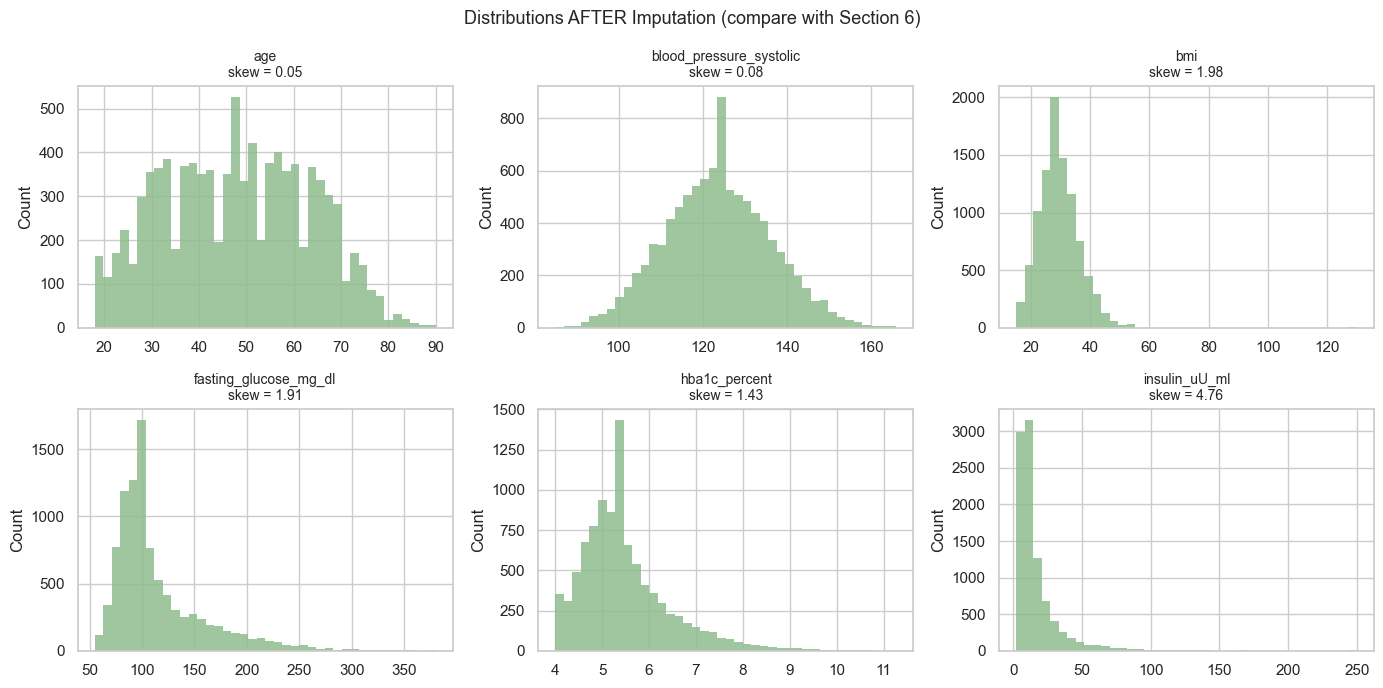

In [17]:
# Distributions AFTER imputation — compare with Section 6 raw histograms

all_imputed_cols = mean_cols + median_cols  # ['age', 'blood_pressure_systolic', 'bmi', 'fasting_glucose_mg_dl', 'hba1c_percent', 'insulin_uU_ml']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for i, col in enumerate(all_imputed_cols):
    axes[i].hist(df[col], bins=40, color='darkseagreen', edgecolor='none', alpha=0.85)
    axes[i].set_title(f'{col}\nskew = {df[col].skew():.2f}', fontsize=10)
    axes[i].set_ylabel('Count')

plt.suptitle('Distributions AFTER Imputation (compare with Section 6)', fontsize=13)
plt.tight_layout()
plt.show()

## 9. Outlier Detection & Treatment

**Why must outliers be handled BEFORE imputation?**

Imputation uses the median (or mean) of existing values. If extreme outliers are still present when we calculate the median, they shift it away from the true centre. Every missing value then gets filled with a biased number.


We use the **IQR method** (Interquartile Range):
- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

We **cap** (Winsorize) values rather than drop rows, to preserve data size. Capping replaces extreme values with the boundary value instead of removing the row entirely.


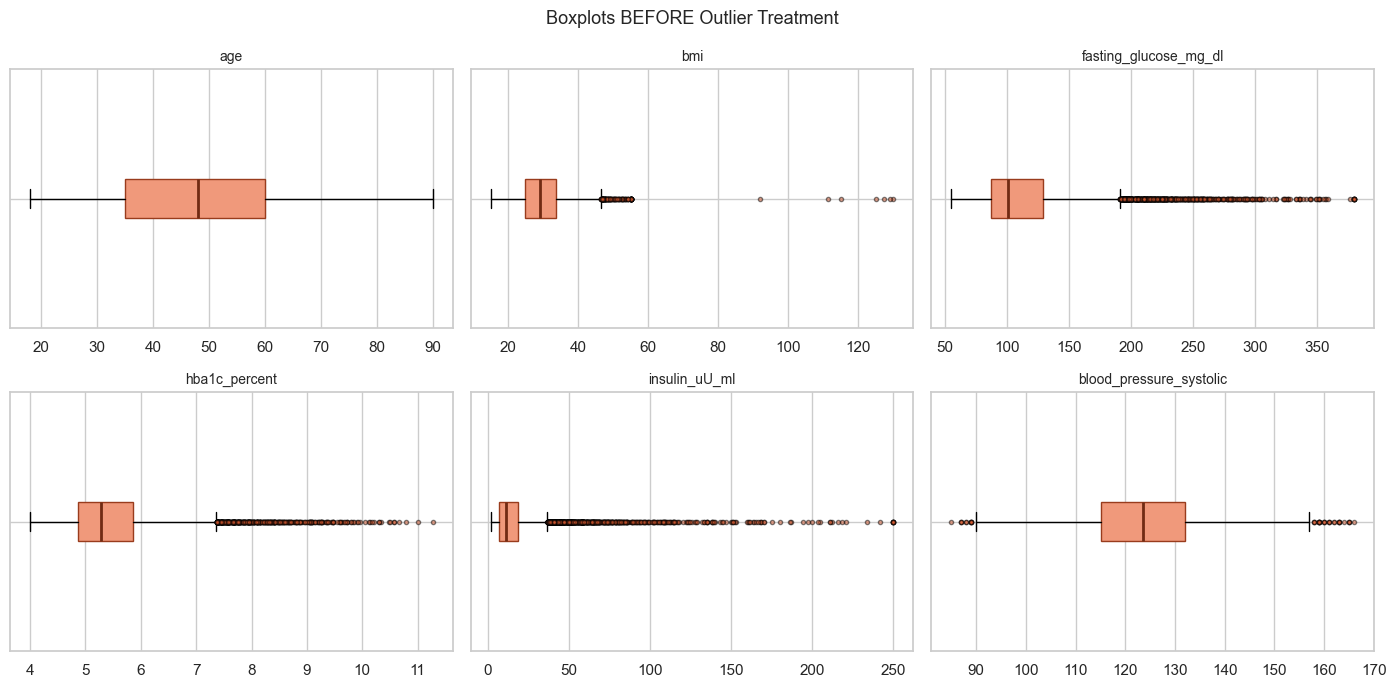

In [18]:
# Boxplots BEFORE outlier treatment

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()
plot_cols = ['age', 'bmi', 'fasting_glucose_mg_dl', 'hba1c_percent',
             'insulin_uU_ml', 'blood_pressure_systolic']

for i, col in enumerate(plot_cols):
    axes[i].boxplot(df[col].dropna(), vert=False, patch_artist=True,
                    boxprops=dict(facecolor='#F0997B', color='#993C1D'),
                    medianprops=dict(color='#712B13', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='#D85A30',
                                   markersize=3, alpha=0.5))
    axes[i].set_title(f'{col}', fontsize=10)
    axes[i].set_yticklabels([])

plt.suptitle('Boxplots BEFORE Outlier Treatment', fontsize=13)
plt.tight_layout()
plt.show()

In [19]:

print('Outlier bounds (IQR × 1.5):')
print(f'  {"Column":<30} {"Lower":>8} {"Upper":>8} {"Outliers":>10}')
print('  ' + '-'*58)

for col in plot_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'  {col:<30} {lower:>8.1f} {upper:>8.1f} {n_out:>10}')
    # Cap values at the bounds instead of dropping rows
    df[col] = df[col].clip(lower=lower, upper=upper)


Outlier bounds (IQR × 1.5):
  Column                            Lower    Upper   Outliers
  ----------------------------------------------------------
  age                                -2.5     97.5          0
  bmi                                12.0     46.4        136
  fasting_glucose_mg_dl              24.9    191.3        733
  hba1c_percent                       3.4      7.4        497
  insulin_uU_ml                     -11.0     36.9        848
  blood_pressure_systolic            89.5    157.5         37


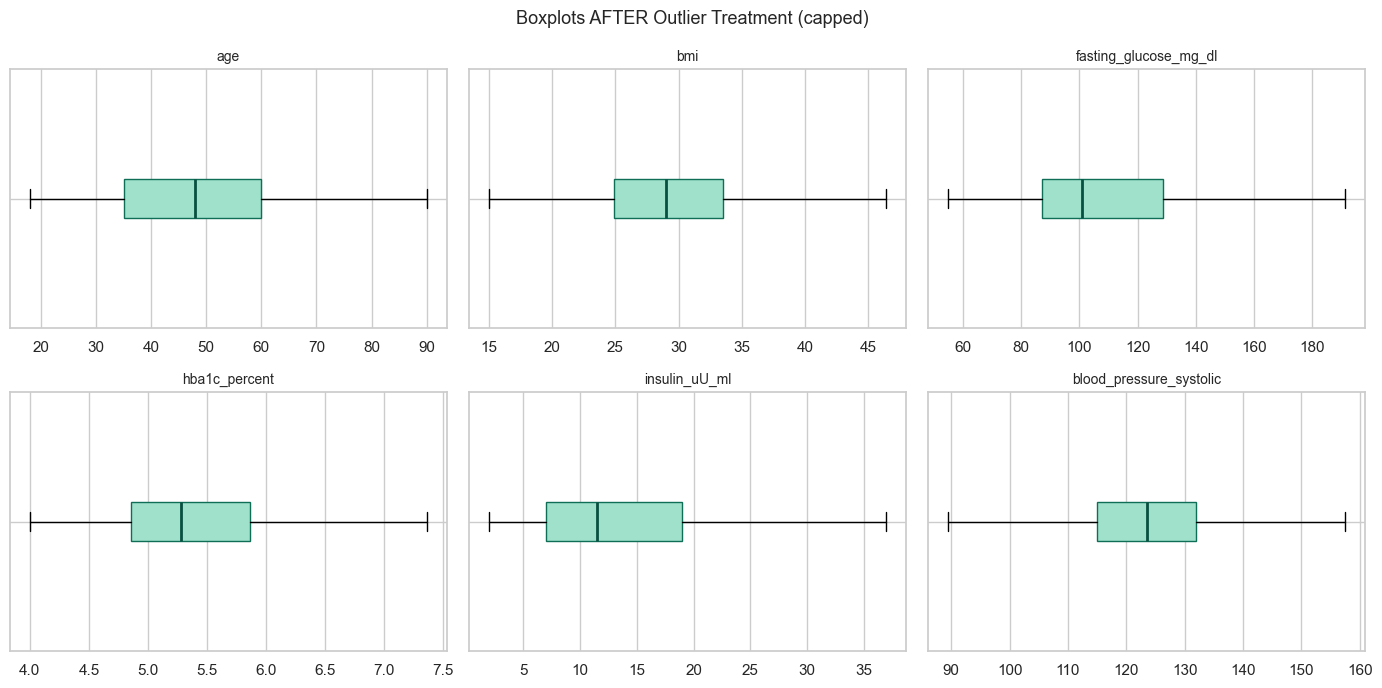

In [20]:
# Boxplots AFTER outlier treatment — compare with before

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    axes[i].boxplot(df[col].dropna(), vert=False, patch_artist=True,
                    boxprops=dict(facecolor='#9FE1CB', color='#0F6E56'),
                    medianprops=dict(color='#085041', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='#1D9E75',
                                   markersize=3, alpha=0.5))
    axes[i].set_title(f'{col}', fontsize=10)
    axes[i].set_yticklabels([])

plt.suptitle('Boxplots AFTER Outlier Treatment (capped)', fontsize=13)
plt.tight_layout()
plt.show()

## 10. Feature Engineering

We create one new numeric feature that combines two of the strongest diabetes predictors:

- `glucose_bmi_ratio` — fasting glucose divided by BMI. A patient with both high glucose and high BMI is at greater risk; this ratio captures that joint signal in a single column.


In [21]:
df['glucose_bmi_ratio'] = (df['fasting_glucose_mg_dl'] / df['bmi']).round(3)

print('Feature engineering completed. Sample:')
print(df[['fasting_glucose_mg_dl', 'bmi', 'glucose_bmi_ratio']].head())


Feature engineering completed. Sample:
   fasting_glucose_mg_dl   bmi  glucose_bmi_ratio
0                   73.6  17.5              4.206
1                  145.1  30.6              4.742
2                   90.7  36.4              2.492
3                  156.4  27.3              5.729
4                  112.1  22.6              4.960


## 11. Encoding Categorical Variables

ML models only understand numbers. We convert categories to numbers.


In [22]:
# Binary encoding for 2-category nominal columns
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
df['family_history_diabetes'] = df['family_history_diabetes'].map({'Yes': 1, 'No': 0})
df['diabetes'] = df['diabetes'].map({'Yes': 1, 'No': 0})

print('Binary encoding done.')
print('gender unique values:', df['gender'].unique())
print('family_history unique:', df['family_history_diabetes'].unique())
print('diabetes unique:      ', df['diabetes'].unique())

Binary encoding done.
gender unique values: [0 1]
family_history unique: [0 1]
diabetes unique:       [0 1]


In [23]:
# Ordinal encoding — preserves the inherent order of each column
activity_order = {'Sedentary': 0, 'Low': 1, 'Moderate': 2, 'High': 3}
df['physical_activity_level'] = df['physical_activity_level'].map(activity_order)

print('Ordinal encoding done.')
print('physical_activity_level values:', sorted(df['physical_activity_level'].unique()))


Ordinal encoding done.
physical_activity_level values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [24]:
print('All dtypes after encoding:')
print(df.dtypes)


All dtypes after encoding:
age                          int64
gender                       int64
bmi                        float64
fasting_glucose_mg_dl      float64
hba1c_percent              float64
insulin_uU_ml              float64
blood_pressure_systolic    float64
family_history_diabetes      int64
physical_activity_level      int64
num_pregnancies              int64
diabetes                     int64
glucose_bmi_ratio          float64
dtype: object


## 12. Correlation Analysis

Before building a model, we check if any two features are
too similar to each other. If they are, the model gets confused
because two columns are saying the same thing.

We use a **correlation heatmap** to check this visually.

**The only rule you need:**
- Each cell shows a number between -1 and +1
- Near 0   → features are independent (good)
- Near +1  → both go up together
- Near -1  → one goes up, other goes down
- |r| > 0.85 → problem — too similar, consider dropping one

The colour makes it easy to spot:
- Dark red  → strong positive relationship
- Dark blue → strong negative relationship  
- White     → no relationship (what we want)


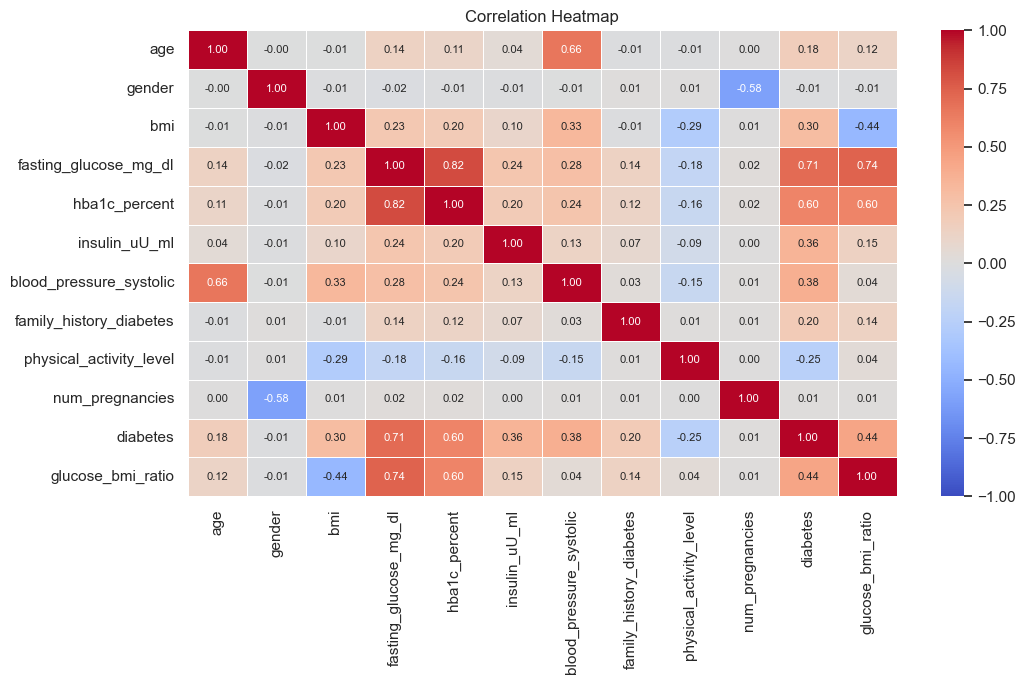

In [25]:
plt.figure(figsize=(11, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={'size': 8})
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# Rule: if |r| > 0.85 between two features (multicollinearity) → consider dropping one
# Our highest pair: fasting_glucose ↔ hba1c = 0.82 → safe to keep both


In [26]:
# num_pregnancies is structurally zero for ALL 5,267 male patients
# This means it perfectly mirrors gender for 50% of the dataset — redundant information
print(df.groupby('gender')['num_pregnancies'].describe())

# Drop it — gender already encodes this information
df.drop(columns=['num_pregnancies'], inplace=True)
print("num_pregnancies dropped. Features remaining:", df.shape[1])

         count      mean       std  min  25%  50%  75%  max
gender                                                     
0       5064.0  1.870458  1.805418  0.0  0.0  2.0  3.0  9.0
1       4475.0  0.000000  0.000000  0.0  0.0  0.0  0.0  0.0
num_pregnancies dropped. Features remaining: 11


### What we found

Only one notable pair exists in our dataset:
- fasting_glucose_mg_dl  ↔  hba1c_percent  →  r = 0.70

Both measure blood sugar so this makes clinical sense.
r = 0.70 is noticeable but below our 0.85 threshold,
so we keep both columns.

All other feature pairs are below r = 0.10 — completely
independent. No features need to be dropped based on
correlation alone.

We also found that num_pregnancies = 0 for every male
patient — a logical dependency on gender. That column
was already dropped in the previous step.

## 13. Train / Test Split

**Why `stratify=y`?**  
Our target is 63% No / 37% Yes. Without stratification, a random split might give the test set 70% No — making evaluation misleading. `stratify=y` guarantees both sets reflect the same 63/37 ratio.

**Why scale after split?**  
Fitting `StandardScaler` on the full dataset before splitting means the scaler has seen test data — this is **data leakage**. We fit *only* on `X_train`, then transform both.


In [27]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f'X_train: {X_train.shape}   X_test: {X_test.shape}')
print(f'y_train: {y_train.shape}   y_test: {y_test.shape}')
print(f'\nClass balance in train: {y_train.value_counts(normalize=True).round(3).to_dict()}')
print(f'Class balance in test:  {y_test.value_counts(normalize=True).round(3).to_dict()}')


X_train: (7631, 10)   X_test: (1908, 10)
y_train: (7631,)   y_test: (1908,)

Class balance in train: {0: 0.627, 1: 0.373}
Class balance in test:  {0: 0.626, 1: 0.374}


In [28]:
# StandardScaler: transforms each feature to mean=0, std=1
# fit ONLY on training data, then transform both

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('Scaling complete.')


Scaling complete.


In [29]:
# Apply SMOTE only on TRAINING data — never on test data!
# This balances the 63/37 class split so every model trains on equal classes.

from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

print('Before SMOTE:', y_train.value_counts().to_dict())
print('After  SMOTE:', y_train_res.value_counts().to_dict())
print(f'Training size went from {len(y_train)} → {len(y_train_res)} rows')


Before SMOTE: {0: 4781, 1: 2850}
After  SMOTE: {0: 4781, 1: 4781}
Training size went from 7631 → 9562 rows


---
# Models

1. **Create** the model object
2. **Train** it on training data
3. **Evaluate** it on test data



## Model 1 — Logistic Regression

**What it does:** Fits a mathematical curve (S-shaped sigmoid) that maps features to a probability of having diabetes. If probability > 0.5 → predicts Yes.

**Best for:** Problems where the relationship between features and outcome is roughly linear. Fast and highly interpretable.

**Needs scaling:** Yes — features on different scales affect the coefficients.


In [30]:
# ── Create & Train ──────────
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_res, y_train_res)

# ── Predict ──────────────
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]  # probability of class 1 (Yes)

print('Logistic Regression trained.')


Logistic Regression trained.


In [31]:
# ── Evaluate ────────────────

print('LOGISTIC REGRESSION — Results')
print(f'Accuracy  : {accuracy_score(y_test, y_pred_lr):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, y_prob_lr):.4f}')

print('\nClassification Report:')
print(classification_report(y_test, y_pred_lr, target_names=['No Diabetes', 'Diabetes']))

LOGISTIC REGRESSION — Results
Accuracy  : 0.8868
ROC-AUC   : 0.9437

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.91      0.91      0.91      1195
    Diabetes       0.85      0.84      0.85       713

    accuracy                           0.89      1908
   macro avg       0.88      0.88      0.88      1908
weighted avg       0.89      0.89      0.89      1908



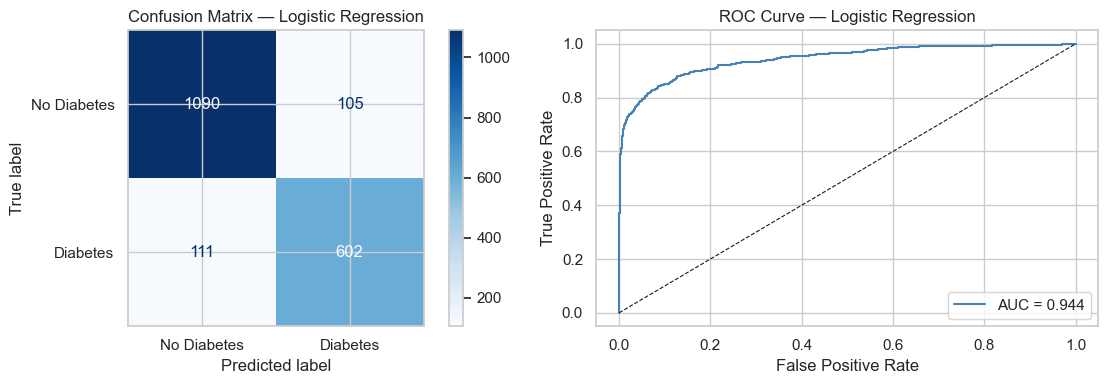

In [32]:
# Confusion Matrix and ROC Curve 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    display_labels=['No Diabetes', 'Diabetes'],
    cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix — Logistic Regression')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_lr)
axes[1].plot(fpr, tpr, color='steelblue', label=f'AUC = {roc_auc_score(y_test, y_prob_lr):.3f}')
axes[1].plot([0,1],[0,1], 'k--', linewidth=0.8)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Logistic Regression')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Model 2 — Decision Tree

**What it does:** Asks a series of yes/no questions about the features (e.g. "Is glucose > 126?") and follows a tree of decisions down to a final prediction.

**Best for:** Easy to visualize and explain. Can capture non-linear patterns.

**Needs scaling:** No — trees split on thresholds, not distances. But scaling doesn't hurt.

**Watch out for:** Without a depth limit (`max_depth`), the tree memorises the training data (overfitting).


In [33]:
from sklearn.tree import DecisionTreeClassifier

# ── Define model ─────────────────
dt = DecisionTreeClassifier(random_state=42)

# ── Define hyperparameter grid ─────────────────
param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

# ── Grid Search ─────────────────
grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

# ── Train ─────────────────
grid_dt.fit(X_train_res, y_train_res)

# ── Best Model ─────────────────
best_dt = grid_dt.best_estimator_

print("Best Parameters:", grid_dt.best_params_)


Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 10}


In [34]:
y_pred_dt = best_dt.predict(X_test_scaled)
y_prob_dt = best_dt.predict_proba(X_test_scaled)[:, 1]

print('Decision Tree trained.')


Decision Tree trained.


In [35]:
# ── Evaluate ──────────

print('DECISION TREE — Results')
print(f'Accuracy  : {accuracy_score(y_test, y_pred_dt):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, y_prob_dt):.4f}')

print('\nClassification Report:')
print(classification_report(y_test, y_pred_dt, target_names=['No Diabetes', 'Diabetes']))


DECISION TREE — Results
Accuracy  : 0.8684
ROC-AUC   : 0.9188

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.89      0.90      0.90      1195
    Diabetes       0.83      0.81      0.82       713

    accuracy                           0.87      1908
   macro avg       0.86      0.86      0.86      1908
weighted avg       0.87      0.87      0.87      1908



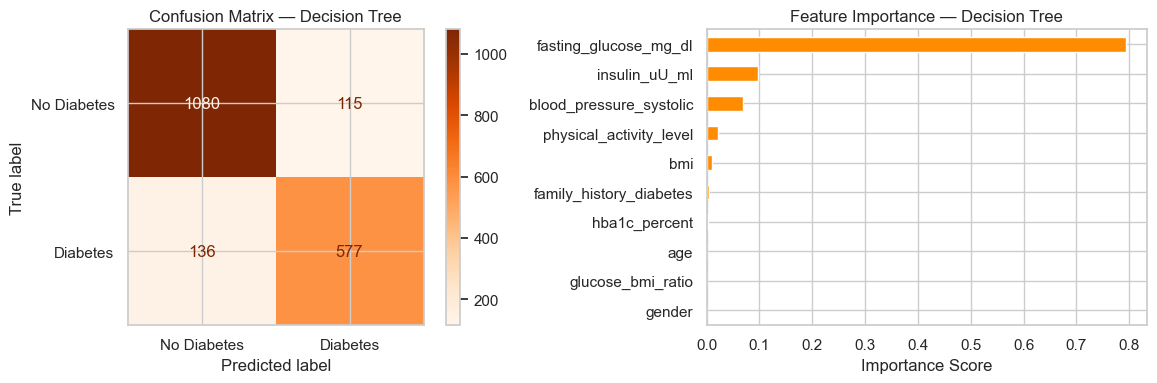

In [36]:
# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dt,
    display_labels=['No Diabetes', 'Diabetes'],
    cmap='Oranges', ax=axes[0])
axes[0].set_title('Confusion Matrix — Decision Tree')

# Feature importance (how often each feature was used to split)
imp_dt = pd.Series(best_dt.feature_importances_, index=X_train.columns).sort_values(ascending=True)
imp_dt.plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Feature Importance — Decision Tree')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()


---
## Model 3 — Random Forest

**What it does:** Builds many Decision Trees (default: 100) on different random subsets of the data and features, then takes a majority vote. More trees = more stable predictions.

**Best for:** Usually the best out-of-the-box performer. Handles non-linear data well and is resistant to overfitting.

**Needs scaling:** No — same as Decision Tree.

**Trade-off:** Less interpretable than a single tree (it's an ensemble of 100 trees).


In [37]:
from sklearn.ensemble import RandomForestClassifier

# ── Base model ───────────────
rf = RandomForestClassifier(random_state=42)

# ── Hyperparameter grid ───────────────
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2']
}

# ── Grid Search ───────────────
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

# ── Train on SMOTE-balanced data ───────────────
grid_rf.fit(X_train_res, y_train_res)

# ── Best model ───────────────
best_rf = grid_rf.best_estimator_

print("Best Parameters:", grid_rf.best_params_)


Best Parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}


In [38]:
y_pred_rf = best_rf.predict(X_test_scaled)
y_prob_rf = best_rf.predict_proba(X_test_scaled)[:, 1]

print('Random Forest trained.')


Random Forest trained.


In [39]:
# ── Evaluate ──────────────

print('       RANDOM FOREST — Results')
print(f'Accuracy  : {accuracy_score(y_test, y_pred_rf):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, y_prob_rf):.4f}')

print('\nClassification Report:')
print(classification_report(y_test, y_pred_rf, target_names=['No Diabetes', 'Diabetes']))


       RANDOM FOREST — Results
Accuracy  : 0.8910
ROC-AUC   : 0.9398

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.90      0.93      0.91      1195
    Diabetes       0.87      0.83      0.85       713

    accuracy                           0.89      1908
   macro avg       0.89      0.88      0.88      1908
weighted avg       0.89      0.89      0.89      1908



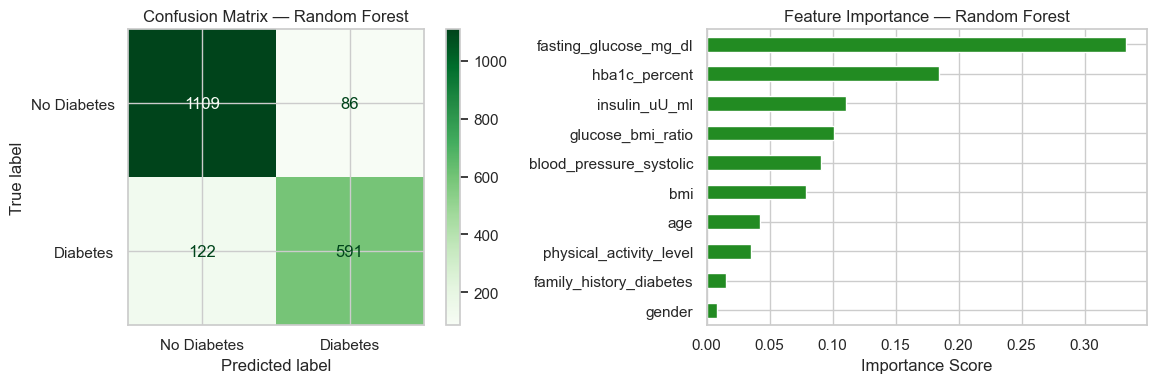

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf,
    display_labels=['No Diabetes', 'Diabetes'],
    cmap='Greens', ax=axes[0])
axes[0].set_title('Confusion Matrix — Random Forest')

imp_rf = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=True)
imp_rf.plot(kind='barh', ax=axes[1], color='forestgreen')
axes[1].set_title('Feature Importance — Random Forest')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()


---
## Model 4 — K-Nearest Neighbors (KNN)

**What it does:** For a new patient, it finds the K most similar patients in the training set (by distance) and takes a majority vote of their labels.

**Best for:** Simple, intuitive, no training phase. Works well when the data has clear local clusters.

**Needs scaling:** Yes — KNN is distance-based, so features on larger scales (e.g. glucose = 120 vs gender = 0/1) would dominate the distance calculation unfairly.

**Watch out for:** Slow on large datasets. The value of K matters a lot — Grid Search will find the best K along with the best distance metric and weighting.


In [41]:
from sklearn.neighbors import KNeighborsClassifier

# ── Base model ───────────────
knn = KNeighborsClassifier()

# ── Hyperparameter grid ───────────────
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# ── Grid Search ───────────────
grid_knn = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

# ── Train on SMOTE-balanced data ───────────────
grid_knn.fit(X_train_res, y_train_res)

# ── Best model ───────────────
best_knn = grid_knn.best_estimator_

print("Best Parameters:", grid_knn.best_params_)


Best Parameters: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}


In [42]:
y_pred_knn = best_knn.predict(X_test_scaled)
y_prob_knn = best_knn.predict_proba(X_test_scaled)[:, 1]

best_k = grid_knn.best_params_['n_neighbors']
print(f'KNN trained with K = {best_k}.')


KNN trained with K = 15.


In [43]:
# ── Evaluate ──────────────

print('       KNN — Results')
print(f'Accuracy  : {accuracy_score(y_test, y_pred_knn):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, y_prob_knn):.4f}')

print('\nClassification Report:')
print(classification_report(y_test, y_pred_knn, target_names=['No Diabetes', 'Diabetes']))

       KNN — Results
Accuracy  : 0.8747
ROC-AUC   : 0.9282

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.89      0.91      0.90      1195
    Diabetes       0.85      0.81      0.83       713

    accuracy                           0.87      1908
   macro avg       0.87      0.86      0.86      1908
weighted avg       0.87      0.87      0.87      1908



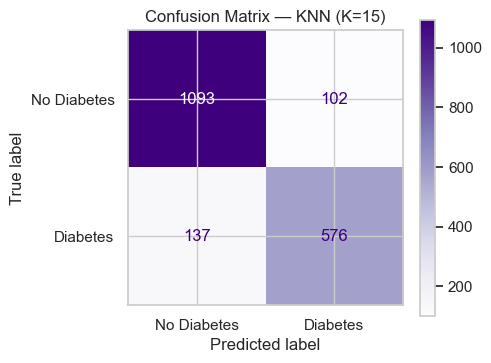

In [44]:
# Confusion Matrix

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn,
    display_labels=['No Diabetes', 'Diabetes'],
    cmap='Purples', ax=ax)
ax.set_title(f'Confusion Matrix — KNN (K={best_k})')
plt.tight_layout()
plt.show()


---
## MODEL COMPARISON

In [45]:

results = []
models_info = [
    ('Logistic Regression', y_pred_lr, y_prob_lr),
    ('Decision Tree',       y_pred_dt, y_prob_dt),
    ('Random Forest',       y_pred_rf, y_prob_rf),
    (f'KNN (K={best_k})',   y_pred_knn, y_prob_knn),
]

for name, y_pred, y_prob in models_info:
    results.append({
        'Model'    : name,
        'Accuracy' : round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall'   : round(recall_score(y_test, y_pred), 4),
        'F1-Score' : round(f1_score(y_test, y_pred), 4),
        'ROC-AUC'  : round(roc_auc_score(y_test, y_prob), 4),
    })

results_df = pd.DataFrame(results).set_index('Model')
print('Model Comparison Table:')
results_df


Model Comparison Table:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8868,0.8515,0.8443,0.8479,0.9437
Decision Tree,0.8684,0.8338,0.8093,0.8214,0.9188
Random Forest,0.8910,0.8730,0.8289,0.8504,0.9398
KNN (K=15),0.8747,0.8496,0.8079,0.8282,0.9282


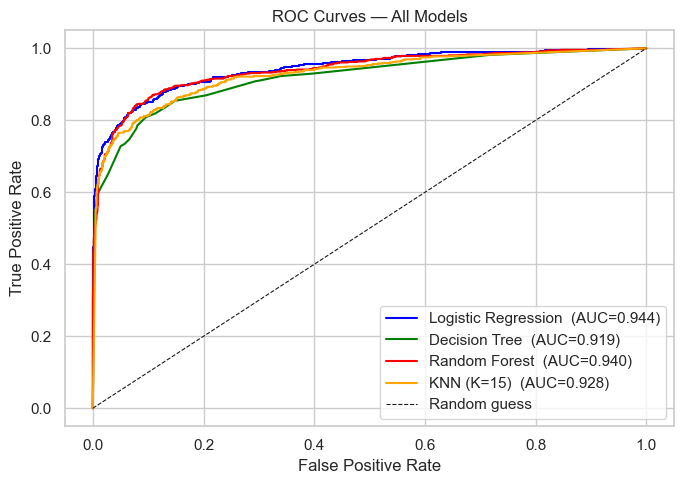

In [46]:
# ROC Curves

plt.figure(figsize=(7, 5))
colors_bar = ['blue', 'green', 'red', 'orange'] 
for (name, y_pred, y_prob), color in zip(models_info, colors_bar):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, color=color, label=f'{name}  (AUC={auc:.3f})')

plt.plot([0,1],[0,1],'k--', linewidth=0.8, label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()